# Base escolhida: [Câncer de mama](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data/data)

O objetivo é desenvolver um modelo de classificação capaz de prever se um
tumor é benigno ou maligno com base em características extraídas de imagens
digitalizadas de massas mamárias.

A variável alvo é diagnosis, que identifica os registros como benignos (B) ou malignos (M). As entradas do modelo são 30 características numéricas relacionadas a medidas de tamanho, forma e textura extraídas das imagens. As colunas id e Unnamed: 32 serão excluídas por representarem, respectivamente, um identificador e uma coluna sem dados.


- B = benigno
- M = maligno


In [100]:
# INSTALAÇÃO DE DEPENDÊNCIAS
%pip install -q numpy pandas matplotlib seaborn missingno scikit-learn

You should consider upgrading via the '/Users/douglas.costa/Projects/fiap-tech-challenge-fase01/env/bin/python3 -m pip install --upgrade pip' command.
You should consider upgrading via the '/Users/douglas.costa/Projects/fiap-tech-challenge-fase01/env/bin/python3 -m pip install --upgrade pip' command.
You should consider upgrading via the '/Users/douglas.costa/Projects/fiap-tech-challenge-fase01/env/bin/python3 -m pip install --upgrade pip' command.
You should consider upgrading via the '/Users/douglas.costa/Projects/fiap-tech-challenge-fase01/env/bin/python3 -m pip install --upgrade pip' command.
You should consider upgrading via the '/Users/douglas.costa/Projects/fiap-tech-challenge-fase01/env/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
You should consider upgrading via the '/Users/douglas.costa/Projects/fiap-tech-challenge-fase01/env/bin/python3 -m pip install --upgrade pip' command.


In [101]:
# IMPORTAÇÃO DAS BIBLIOTECAS QUE SERÃO UTILIZADAS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno
from sklearn.preprocessing import LabelEncoder
import seaborn as sb
import math

# Passo 01
Entender a base de dados: suas dimensões, tipos, valores ausentes e estatísticas descritivas.

In [121]:
dados = pd.read_csv("database/data.csv")

In [103]:
len(dados.columns)

33

In [122]:
dados.shape

(569, 33)

In [105]:
dados.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [106]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

# Passo 02
Identificar valores ausentes, fazer os ajustes necessários e remover a coluna `id`, pois ela não possui valor preditivo para o modelo.

In [107]:
# IDENTIFICADO COLUNA DE ID, ELA NÃO  RELEVANTE PARA TREINAR O MODELO VAMOS TRATAR MAIS ABAIXO
dados.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


Como podemos constatar, a coluna `Unnamed: 32` está vazia em 100% dos registros. Portanto, vamos desconsiderá-la.

<Axes: >

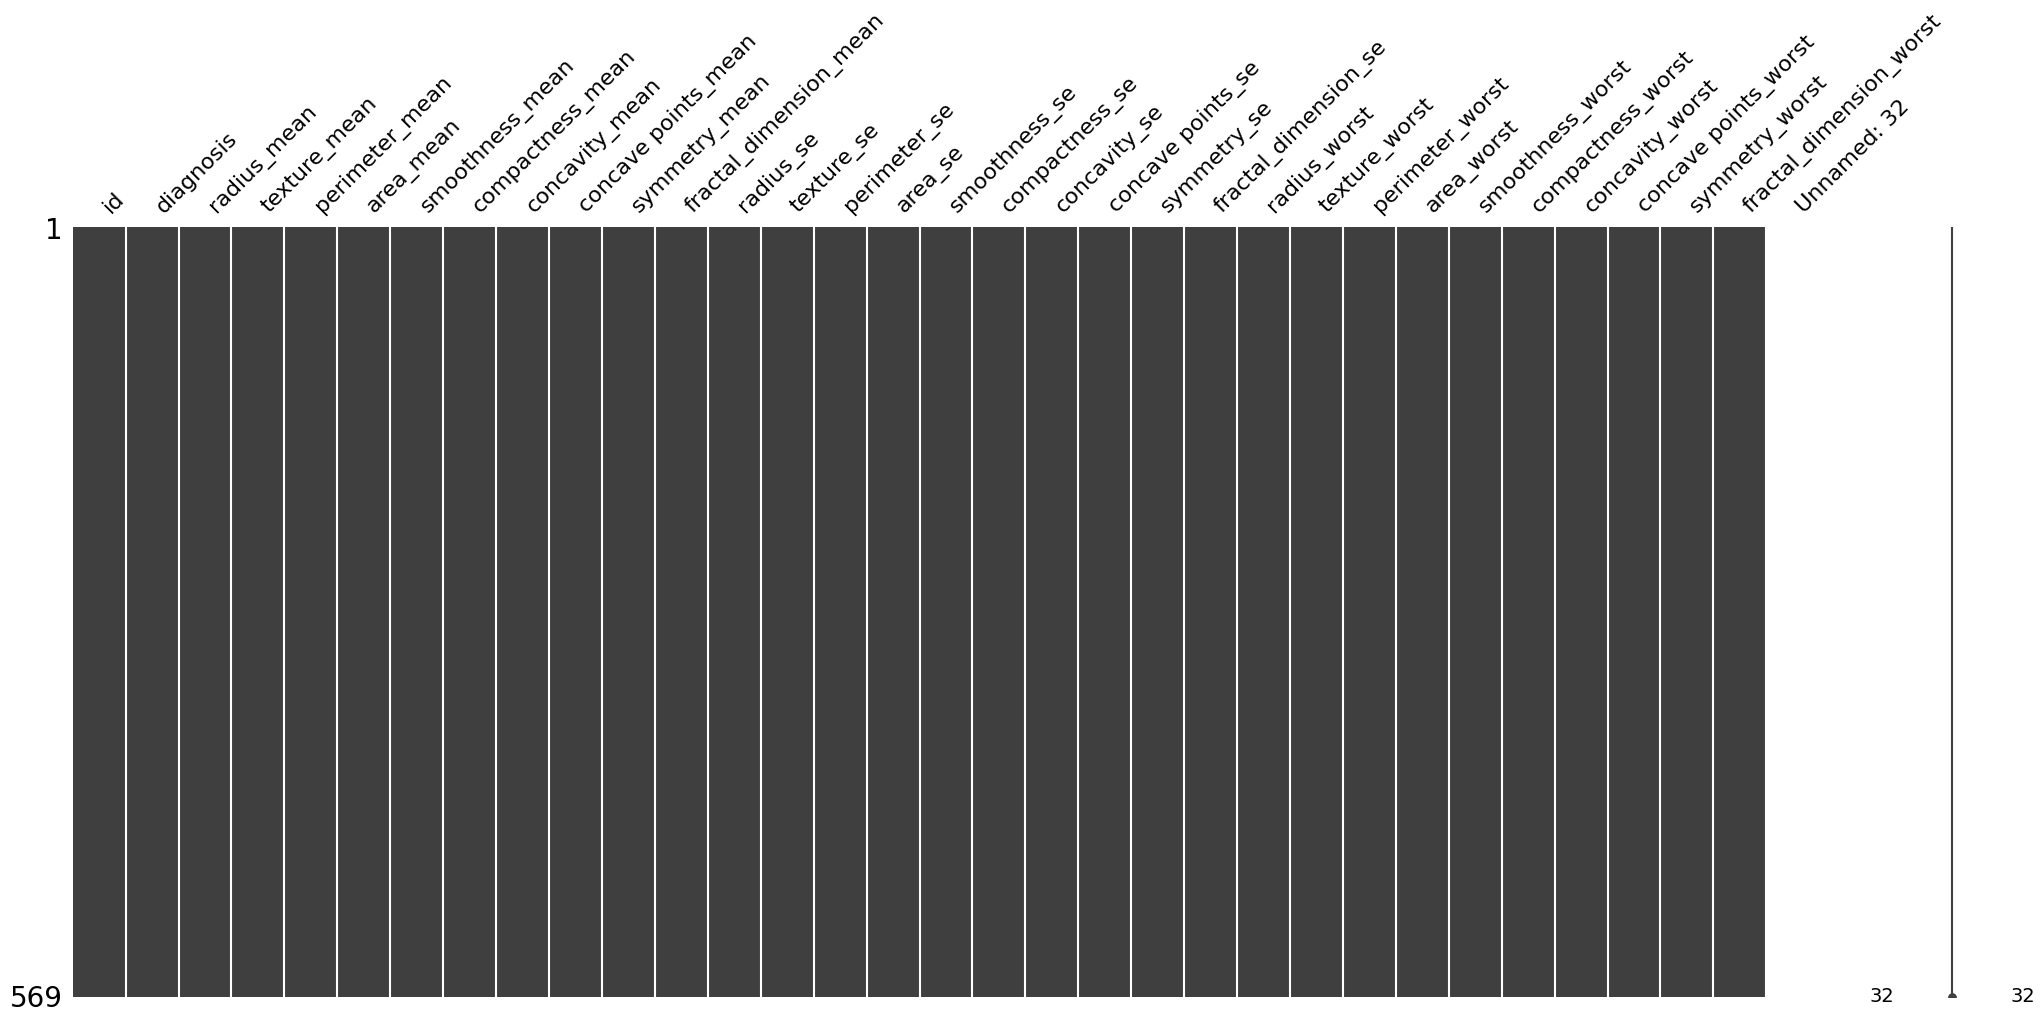

In [108]:
msno.matrix(dados)

In [109]:
if "Unnamed: 32" in dados.columns:
    dados.drop("Unnamed: 32", axis=1, inplace=True)

if "id" in dados.columns:
    dados.drop("id", axis=1, inplace=True)

dados.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [120]:
print("Duplicados:", dados.duplicated().sum())
print("Valores ausentes:", dados.isna().sum().sum())

Duplicados: 0
Valores ausentes: 0


# Passo 03
Neste projeto, o diagnóstico será codificado numericamente para facilitar as análises e a identificação da classe positiva. A única variável categórica é `diagnosis`, justamente a nossa classe alvo.

Usaremos o `LabelEncoder()` para representar:

B = benigno
M = maligno

como:
B = 0
M = 1

In [111]:
# OS DADOS ESTAO SENDO CLASSIFICADOS ENTRE MALIGNO E BENIGNO, TEREMOS QUE USAR UMA ESTRATEGIA
# DE TRANSFORMACAO NOS DADOS
# B = benigno
# M = maligno
set(dados['diagnosis'])

# B = 0
# M = 1


{'B', 'M'}

In [112]:
# APLICANDO A TECNICA DE LABEL ENCODE JÁ QUE TEMOS APENAS DE CATEGORIAS QUE PDOE SER REPRESENTADA
# POR 0 E 1 
label = LabelEncoder()

dados['diagnosis'] = label.fit_transform(dados['diagnosis'])

In [113]:
dados.head()


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# Passo 04 
São 357 registros benignos (62,7%) e 212 malignos (37,3%). A divisão será estratificada para preservar essas proporções, sem necessidade automática de balanceamento artificial.

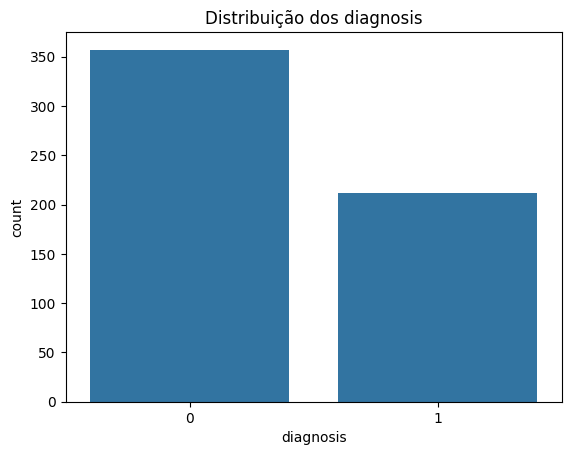

In [114]:
sb.countplot(data=dados, x="diagnosis")
plt.title("Distribuição dos diagnosis")
plt.show()

# Passo 05
Vamos analisar a distribuição dos dados e os possíveis outliers.
No boxplot, a caixa contém os 50% centrais dos valores, e a linha dentro dela representa a mediana. Os pontos fora dos bigodes indicam possíveis outliers.

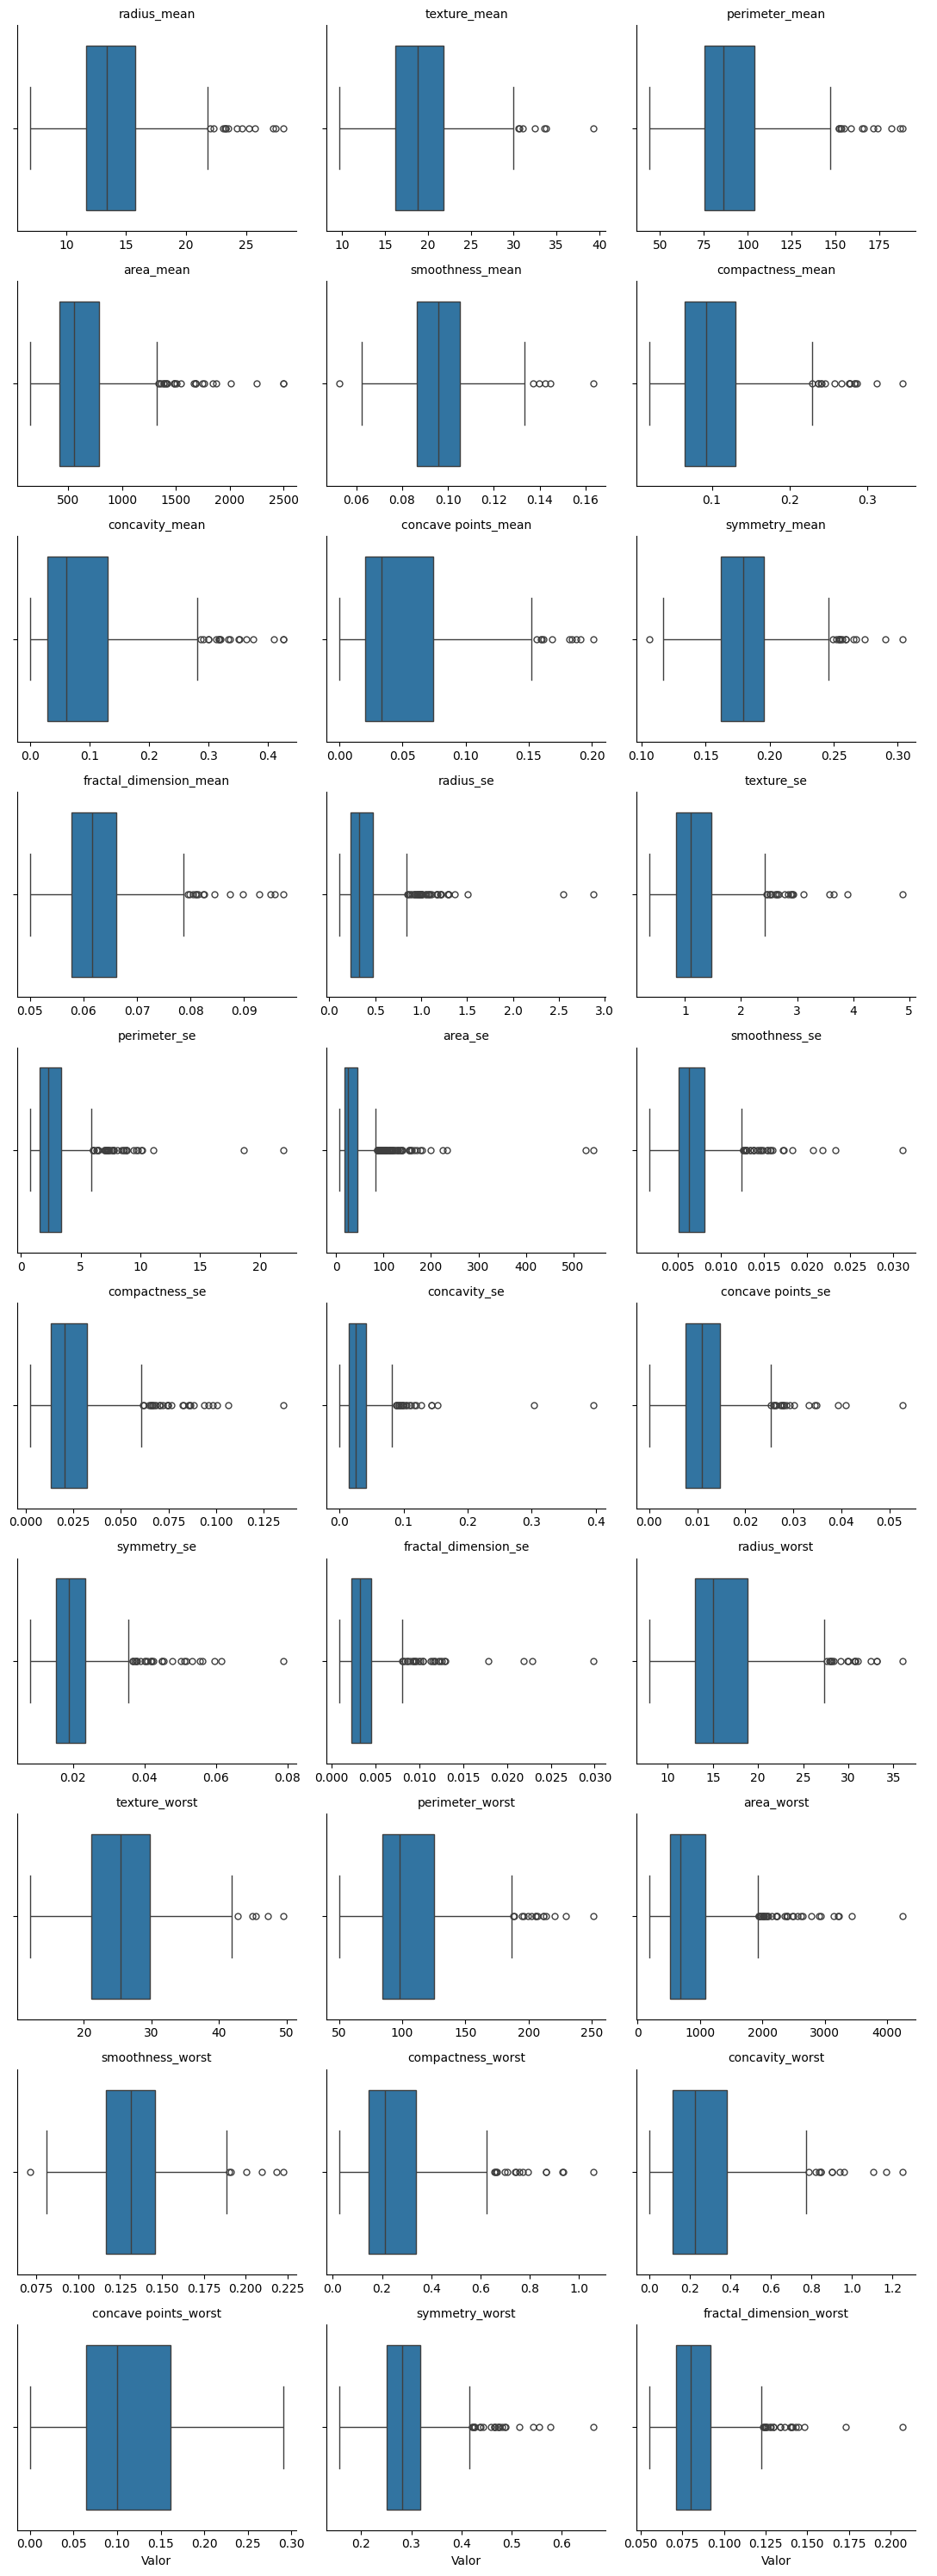

In [115]:
numericas = dados.drop(columns="diagnosis").select_dtypes(include="number")
dados_longos = numericas.melt(
    var_name="Coluna",
    value_name="Valor"
)

g = sb.catplot(
    data=dados_longos,
    x="Valor",
    col="Coluna",
    kind="box",
    col_wrap=3,
    sharex=False,
    sharey=False,
    height=3,
    aspect=1.2
)

g.set_titles("{col_name}")

Os boxplots mostram valores extremos em variáveis como `perimeter_mean` e `area_mean`. Esses valores serão mantidos inicialmente, pois outliers não representam automaticamente erros na base. Posteriormente, vamos analisar sua relação com o diagnóstico e decidir o tratamento adequado.

Com o histograma, conseguimos analisar a frequência dos valores, suas concentrações e caudas. Em diversas características, a maior concentração aparece nas faixas menores, enquanto poucos valores elevados formam uma cauda à direita.

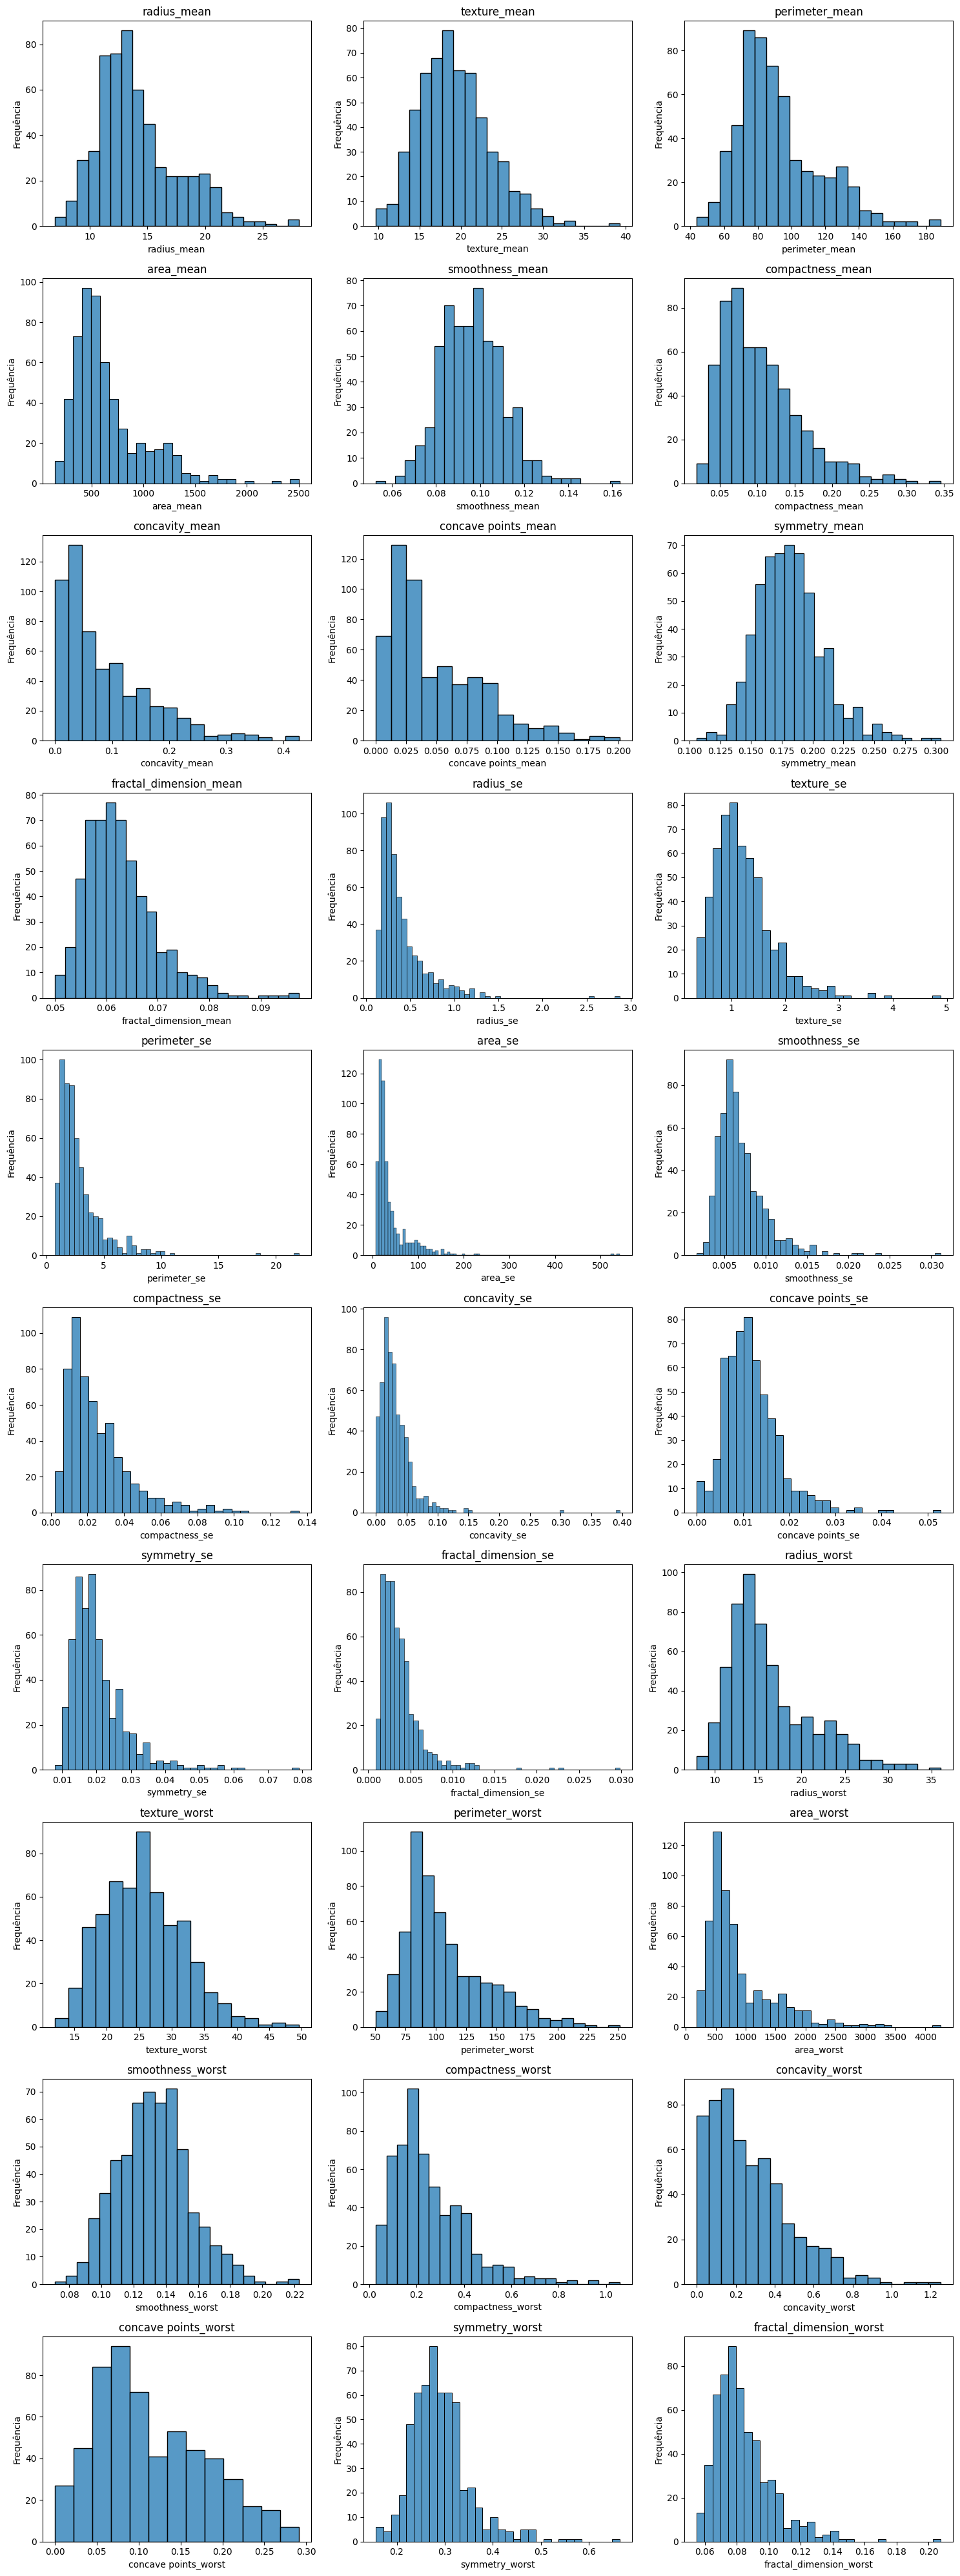

In [116]:
colunas = dados.drop(columns="diagnosis").select_dtypes(include="number").columns

por_linha = 3
linhas = math.ceil(len(colunas) / por_linha)

fig, axes = plt.subplots(
    linhas, por_linha,
    figsize=(15, 4 * linhas),
    squeeze=False
)

for ax, coluna in zip(axes.flat, colunas):
    sb.histplot(data=dados, x=coluna, ax=ax)
    ax.set_title(coluna)
    ax.set_ylabel("Frequência")

# Remove os espaços que sobraram na grade
for ax in list(axes.flat)[len(colunas):]:
    ax.remove()

plt.tight_layout()
plt.show()

A seguir, comparamos a distribuição de `perimeter_mean` entre os diagnósticos. Os registros malignos tendem a apresentar valores maiores, mas existe sobreposição entre os grupos. Portanto, essa característica isoladamente não separa perfeitamente os diagnósticos.

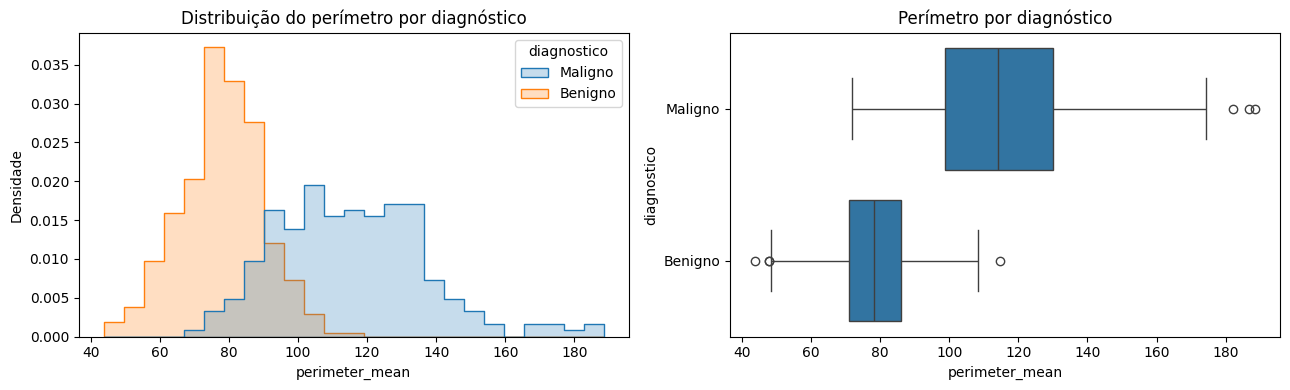

In [117]:
visualizacao = dados.assign(
    diagnostico=dados["diagnosis"].map({0: "Benigno", 1: "Maligno"})
)
paleta_diagnostico = {"Benigno": "#2ca02c", "Maligno": "#d62728"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sb.histplot(
    data=visualizacao,
    x="perimeter_mean",
    hue="diagnostico",
    palette=paleta_diagnostico,
    bins=25,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[0]
)
axes[0].set_title("Distribuição do perímetro por diagnóstico")
axes[0].set_ylabel("Densidade")

sb.boxplot(
    data=visualizacao,
    x="perimeter_mean",
    y="diagnostico",
    hue="diagnostico",
    palette=paleta_diagnostico,
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Perímetro por diagnóstico")

plt.tight_layout()
plt.show()

A matriz mostra correlações positivas relevantes entre o diagnóstico e características relacionadas ao tamanho e à irregularidade dos núcleos celulares. As maiores correlações com a classe alvo foram observadas em `concave points_worst`, `perimeter_worst`, `concave points_mean` e `radius_worst`, com valores próximos de 0,78. Como a classe maligna foi codificada como 1, valores maiores dessas características estão associados aos casos malignos nesta base. Também foram encontradas correlações muito altas entre raio, perímetro e área, indicando que algumas características carregam informações semelhantes. Correlação representa associação linear, não causalidade, e não garante que uma característica isolada determine o diagnóstico.

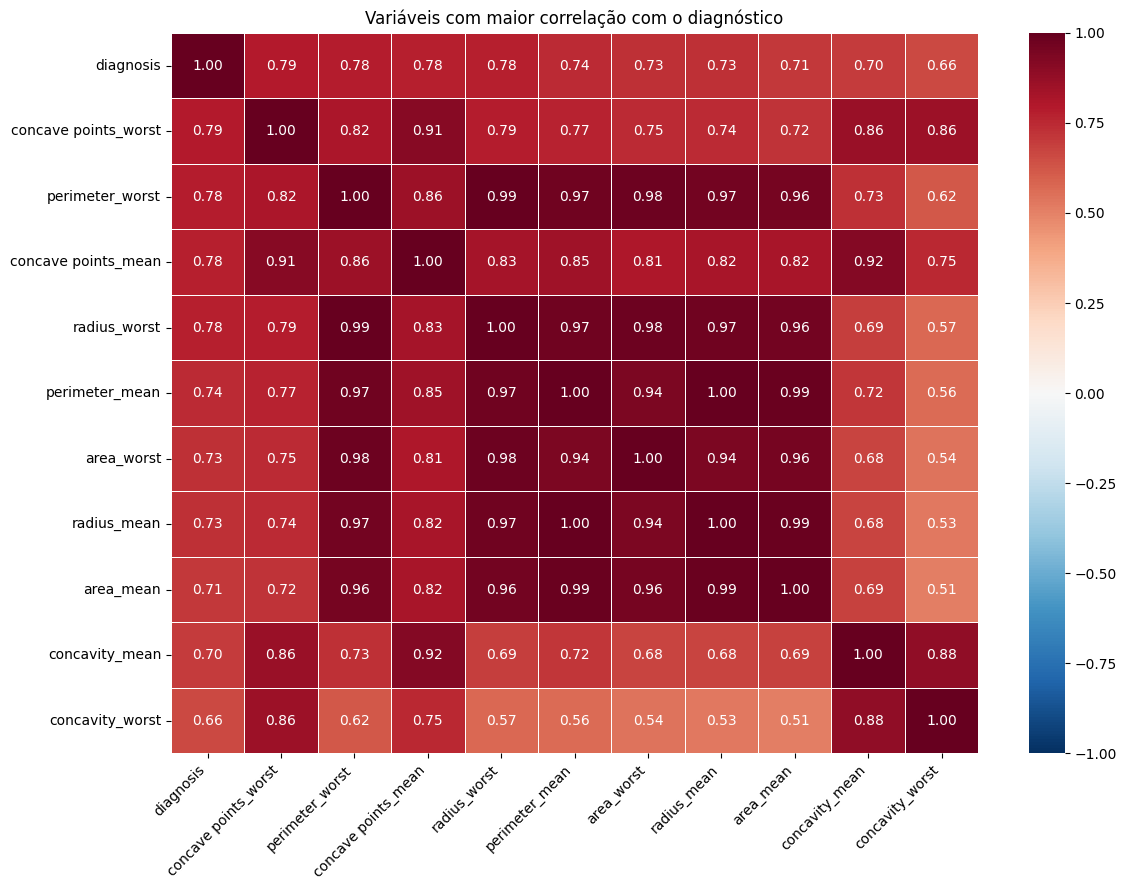

In [118]:
# Calcula as correlações
correlacoes = dados.corr(numeric_only=True)

# Seleciona as 10 maiores correlações com o diagnóstico
mais_correlacionadas = (
    correlacoes["diagnosis"]
    .drop("diagnosis")
    .dropna()
    .abs()
    .nlargest(10)
    .index
)

# Inclui o diagnóstico na matriz reduzida
colunas = ["diagnosis"] + mais_correlacionadas.tolist()
matriz_menor = correlacoes.loc[colunas, colunas]

# Desenha o gráfico
fig, ax = plt.subplots(figsize=(12, 9))

sb.heatmap(
    matriz_menor,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    ax=ax
)

ax.set_title("Variáveis com maior correlação com o diagnóstico")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

As características selecionadas apresentam associação linear relevante com o diagnóstico, mas isso não significa que determinem a classe isoladamente. Para facilitar a visualização das distribuições e da sobreposição entre as classes, vamos analisar no `pairplot` as três características com maior correlação absoluta com o diagnóstico.

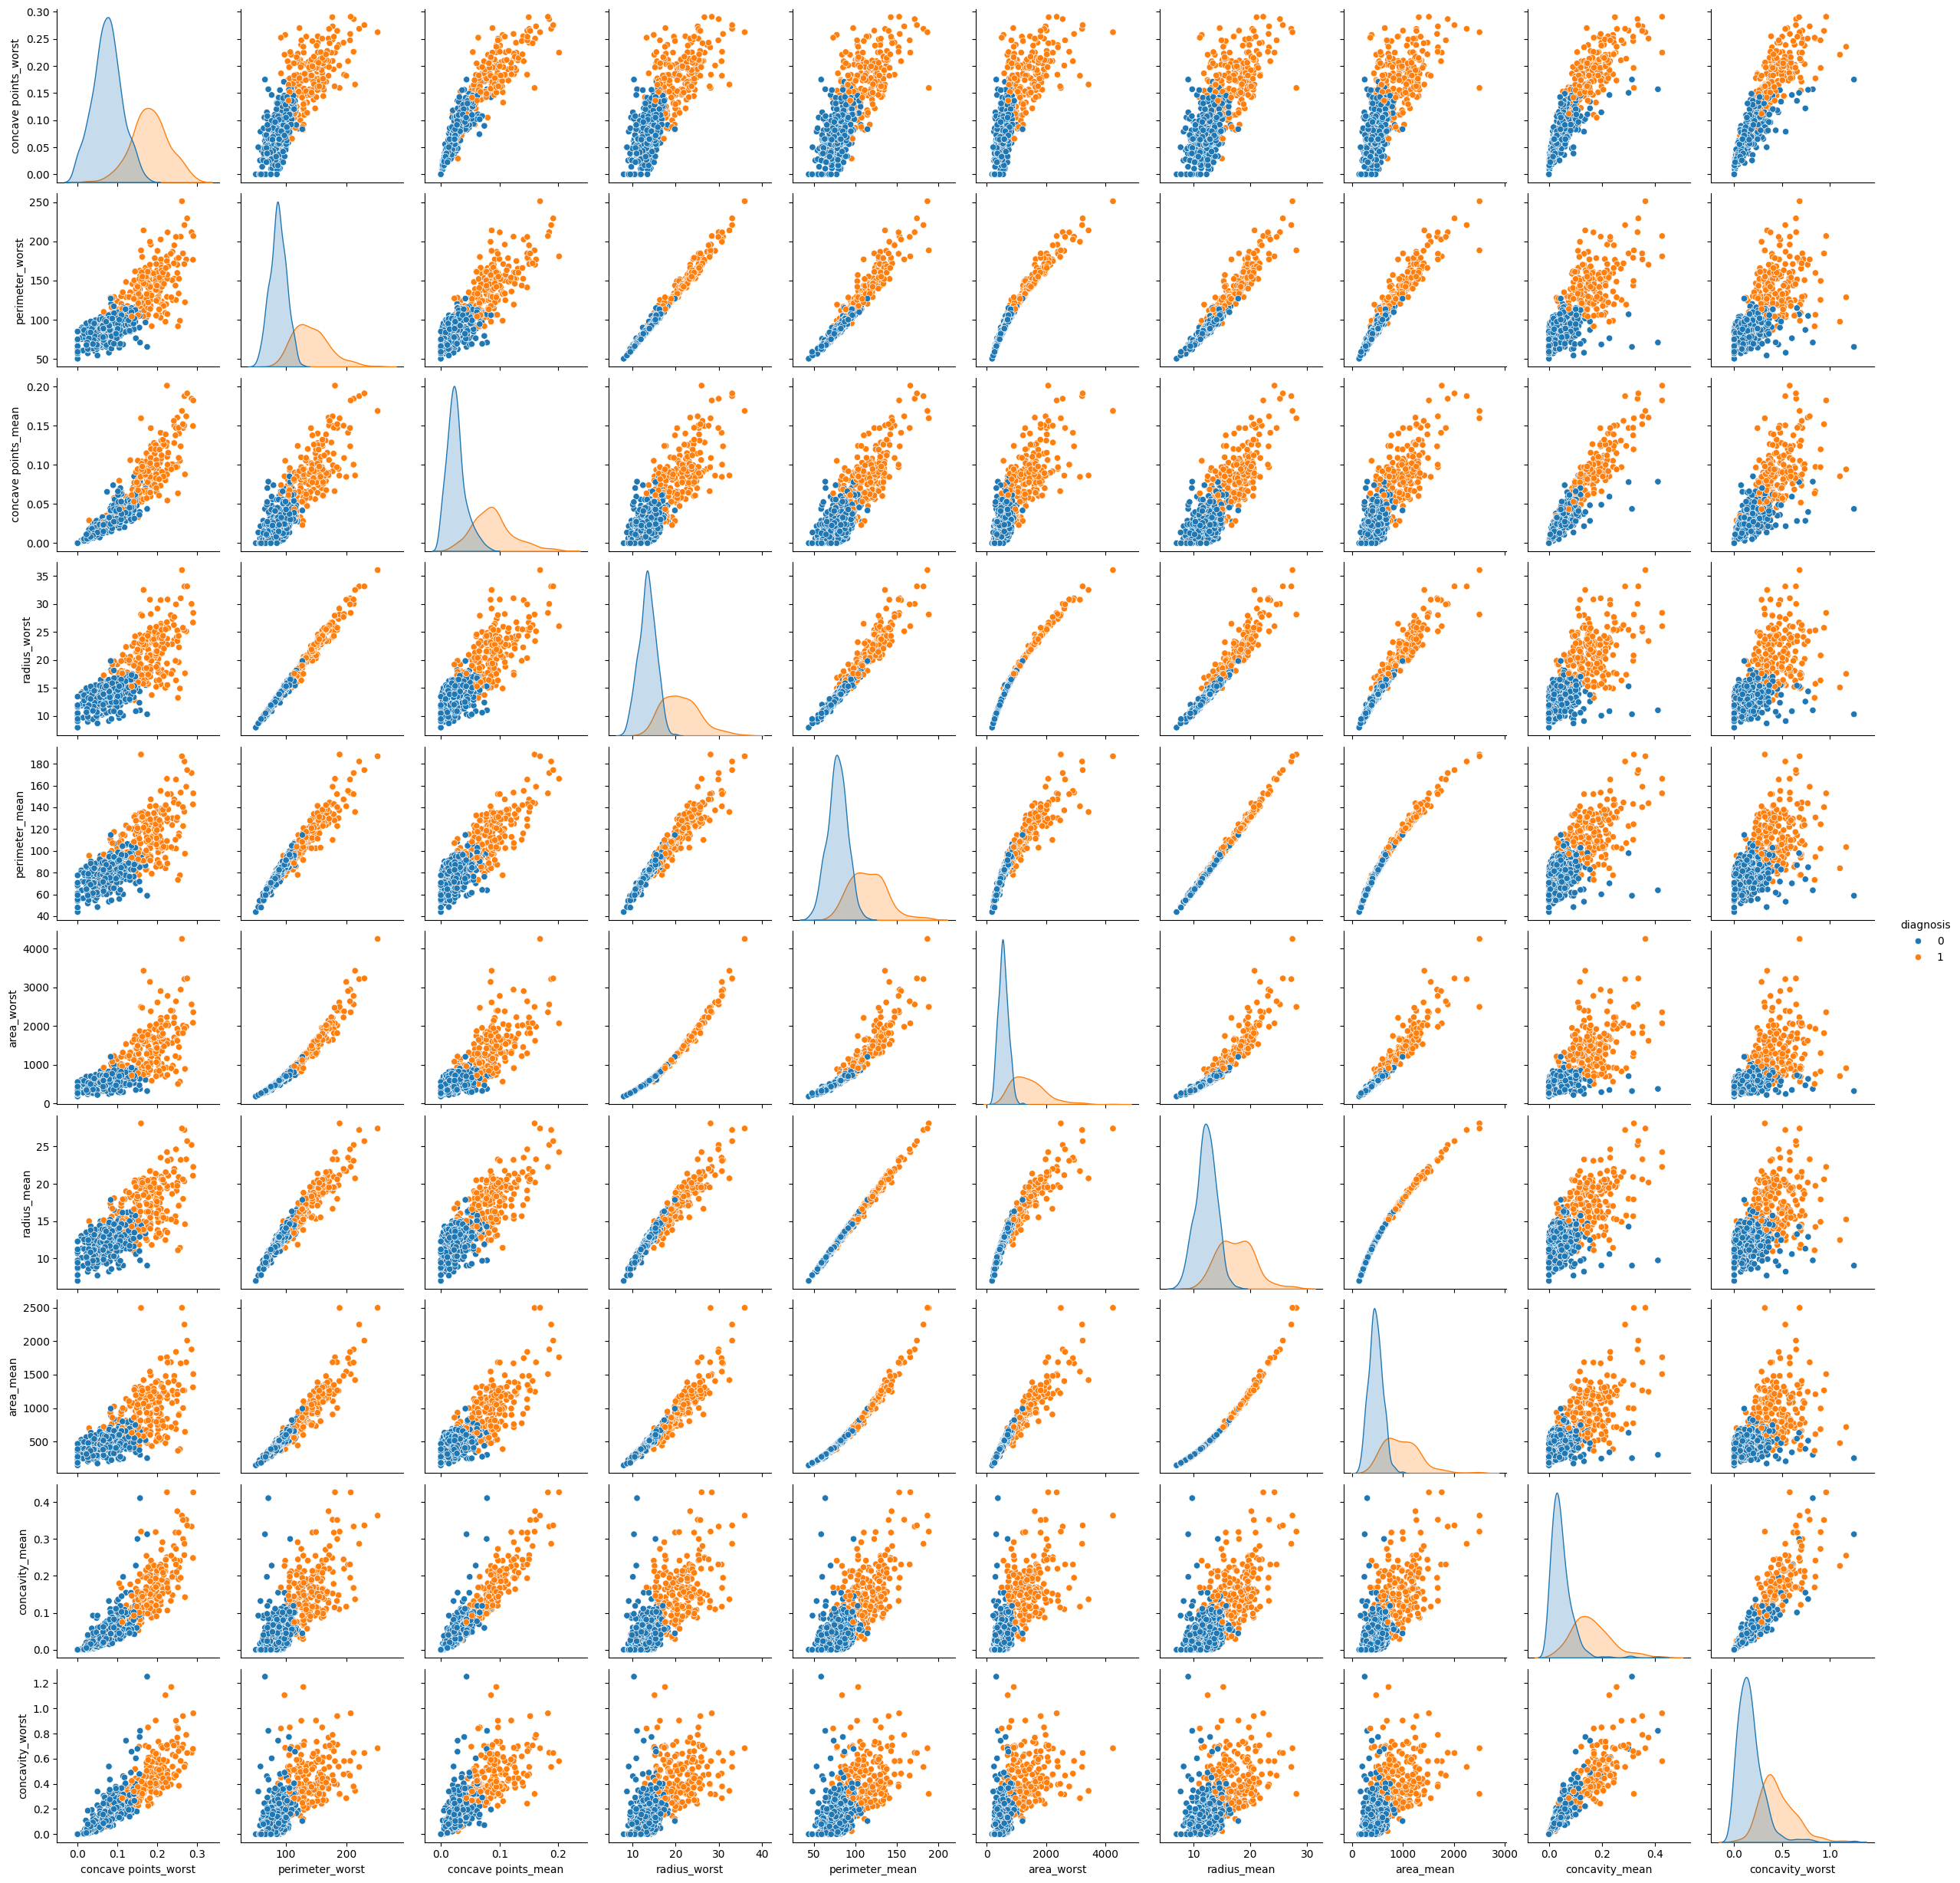

In [119]:
variaveis_pairplot = [
    "concave points_worst",
    "perimeter_worst",
    "concave points_mean"
]

sb.pairplot(
    data=visualizacao,
    vars=variaveis_pairplot,
    hue="diagnostico",
    hue_order=["Benigno", "Maligno"],
    palette=paleta_diagnostico,
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.6}
)
plt.show()

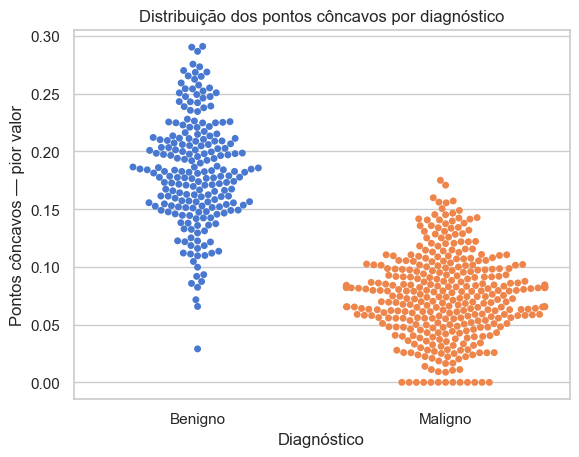

In [130]:
sb.set_theme(style="whitegrid")
plt.figure(figsize=(10, 4))

ax = sb.stripplot(
    data=visualizacao,
    x="concave points_worst",
    y="diagnostico",
    order=["Benigno", "Maligno"],
    hue="diagnostico",
    palette=paleta_diagnostico,
    jitter=0.25,
    alpha=0.6,
    size=4,
    legend=False
)

ax.set(
    xlabel="Média dos três maiores valores de pontos côncavos",
    ylabel="Diagnóstico",
    title="Distribuição dos pontos côncavos por diagnóstico"
)

plt.tight_layout()
plt.show()

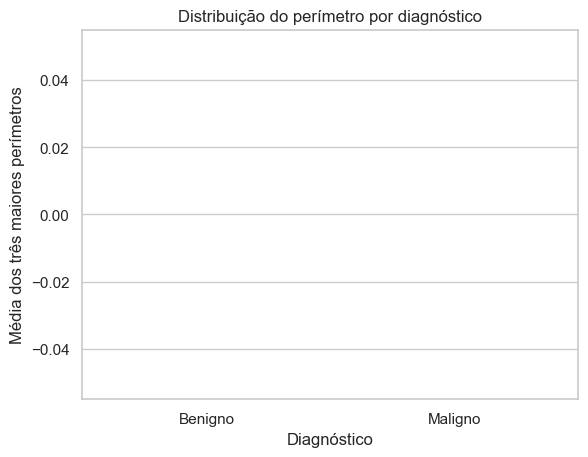

In [ ]:
visualizacao = dados.assign(
    diagnostico=dados["diagnosis"].map({0: "Benigno", 1: "Maligno"})
)

sb.set_theme(style="whitegrid")
plt.figure(figsize=(10, 4))

ax = sb.stripplot(
    data=visualizacao,
    x="perimeter_worst",
    y="diagnostico",
    order=["Benigno", "Maligno"],
    hue="diagnostico",
    palette=paleta_diagnostico,
    jitter=0.25,
    alpha=0.6,
    size=4,
    legend=False
)

ax.set(
    xlabel="Média dos três maiores perímetros",
    ylabel="Diagnóstico",
    title="Distribuição do perímetro por diagnóstico"
)

plt.tight_layout()
plt.show()